# GACI exploration notebook

Interactive exploration of the saved experiment artifacts. **No models are
retrained and no experiments are rerun** — every cell loads
`results/*_series.npz` and `results/*_metrics.json` / `ci_metrics.json`, so
the notebook is deterministic and cheap. Canonical figures for the
manuscripts are generated by `experiments/figures.py`; this notebook is for
exploration only.

Environment: `conda activate credit-risk_VENV` (Python 3.13, CPU).

Encoding conventions (matching `experiments/figures.py`, Okabe-Ito):
- color = method: SCP black, ACI vermilion `#D55E00`, GACI blue `#0072B2`, GACI-pooled green `#009E73`
- marker = domain: Lending Club `o`, Electricity `s`
- target coverage `1 - alpha = 0.90` shown as a dotted reference line

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RES = Path("../results").resolve()
ALPHA = 0.10
TARGET = 1 - ALPHA
COLORS = {"SCP": "#000000", "ACI": "#D55E00", "GACI": "#0072B2",
          "GACI-pooled": "#009E73"}

e4 = np.load(RES / "e4_series.npz", allow_pickle=True)
m4 = json.loads((RES / "e4_metrics.json").read_text())
m5 = json.loads((RES / "e5_metrics.json").read_text())
m6 = json.loads((RES / "e6_metrics.json").read_text())
m10 = json.loads((RES / "e10_metrics.json").read_text())
ci = json.loads((RES / "ci_metrics.json").read_text())

def rolling(cov, w=2000):
    """Centered rolling mean coverage over the stream."""
    s = pd.Series(np.asarray(cov, dtype=float))
    return s.rolling(w, center=True, min_periods=w // 4).mean().to_numpy()

print("loaded:", {p.name: p.stat().st_size for p in RES.glob("*.npz")})

loaded: {'e1_series.npz': 1663192, 'e5_series.npz': 6456771, 'e2_series.npz': 5594745, 'e3_series.npz': 6373432, 'e4_series.npz': 4833270}


## 1. The masking phenomenon — per-grade coverage trajectories (E4)

Marginal ACI (vermilion) vs per-group GACI (blue), rolling coverage over
the 70k-loan stream. Grade G is the headline failure: ACI sits near 0.23
while GACI tracks the 0.90 target. Grades are ordered by risk (A best → G
worst); note how ACI *over*-covers easy grades while failing hard ones —
marginal coverage is an average that hides both directions.

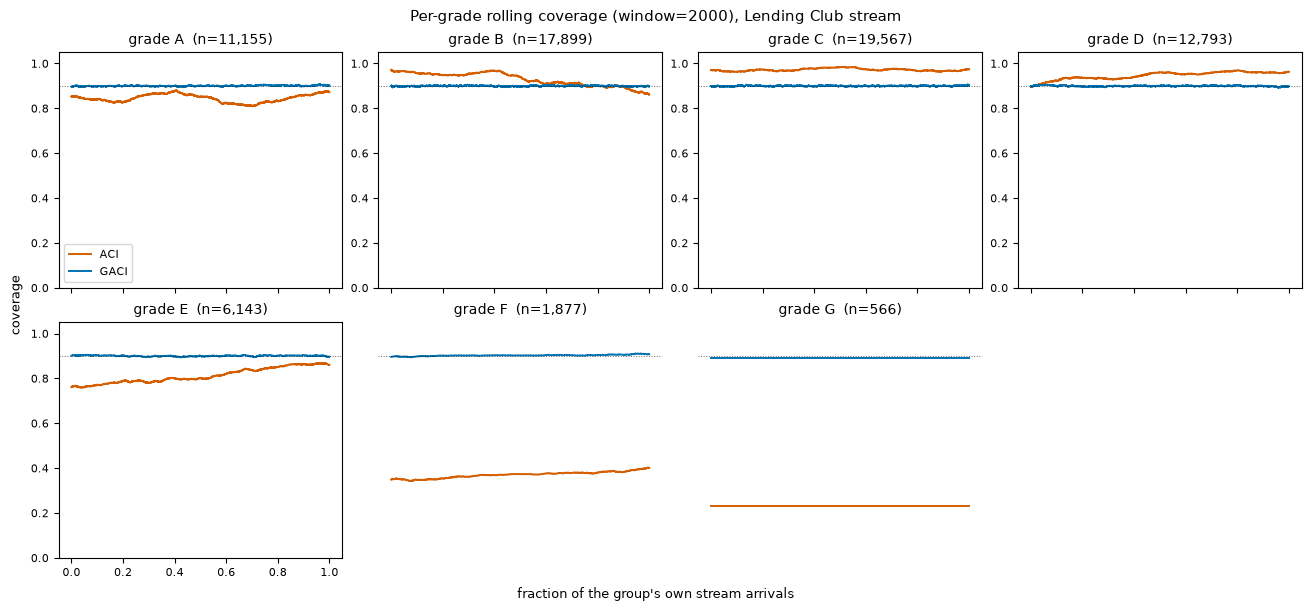

In [2]:
groups = e4["groups"]
order = ["A", "B", "C", "D", "E", "F", "G"]
fig, axes = plt.subplots(2, 4, figsize=(13, 6), layout="constrained",
                     sharex=True)
axes = axes.ravel()
for ax, g in zip(axes, order):
    mask = groups == g
    n = int(mask.sum())
    for name, key, covkey in [("ACI", "aci", "aci_cov"),
                              ("GACI", "gaci", "gaci_cov")]:
        r = rolling(e4[covkey][mask])
        xs = np.arange(len(r)) / max(n - 1, 1)
        ax.plot(xs, r, color=COLORS[name], lw=1.4, label=name)
    ax.axhline(TARGET, color="k", lw=0.7, ls=":", alpha=0.6)
    ax.set_title(f"grade {g}  (n={n:,})", fontsize=10)
    ax.set_ylim(0, 1.05)
    ax.tick_params(labelsize=8)
axes[0].legend(fontsize=8, loc="lower left")
for ax in axes[-3:]:
    ax.axis("off")
fig.suptitle("Per-grade rolling coverage (window=2000), Lending Club stream",
             fontsize=11)
fig.supxlabel("fraction of the group's own stream arrivals", fontsize=9)
fig.supylabel("coverage", fontsize=9)
plt.show()

## 2. Width is reallocated, not multiplied (E4 + ci_metrics)

The corrected cost story: GACI's *mean* width is slightly smaller than
marginal ACI's (0.107 vs 0.113), but per-grade widths diverge — hard grades
get wider intervals, easy grades narrower. Whiskers are block-bootstrap
95% CIs (10 contiguous stream blocks, 20k resamples; `ci_metrics.json`).

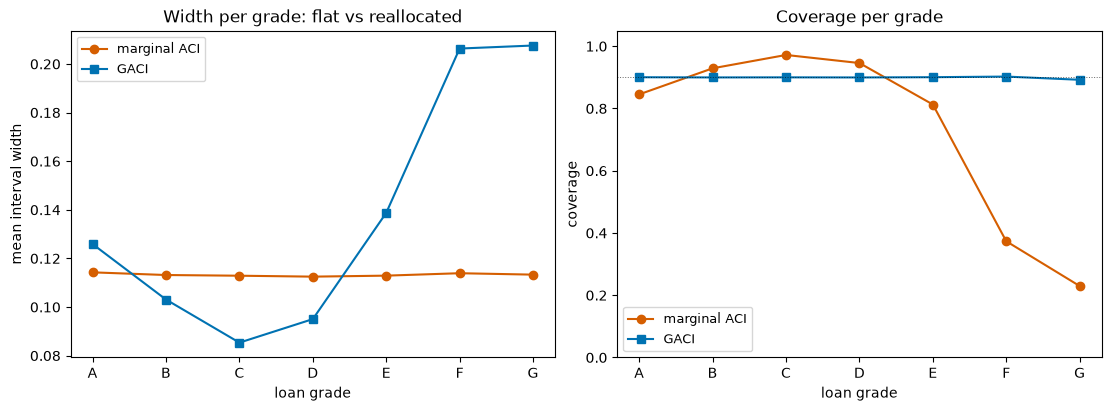

mean width  ACI=0.1131  GACI=0.1070  SCP=0.1029
aci   width 0.1131  95% CI [0.1084, 0.1177]
gaci  width 0.1070  95% CI [0.1027, 0.1111]


In [3]:
pg = m4["gaci"]["per_group"]
pa = m4["aci_per_group"]
x = np.arange(len(order))
w_gaci = np.array([pg[g]["mean_width"] for g in order])
w_aci = np.array([pa[g]["mean_width"] for g in order])
cov_gaci = np.array([pg[g]["coverage"] for g in order])
cov_aci = np.array([pa[g]["coverage"] for g in order])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
ax1.plot(x, w_aci, "o-", color=COLORS["ACI"], label="marginal ACI")
ax1.plot(x, w_gaci, "s-", color=COLORS["GACI"], label="GACI")
ax1.set_xticks(x, order)
ax1.set_xlabel("loan grade")
ax1.set_ylabel("mean interval width")
ax1.set_title("Width per grade: flat vs reallocated")
ax1.legend(fontsize=9)
ax2.plot(x, cov_aci, "o-", color=COLORS["ACI"], label="marginal ACI")
ax2.plot(x, cov_gaci, "s-", color=COLORS["GACI"], label="GACI")
ax2.axhline(TARGET, color="k", lw=0.7, ls=":", alpha=0.6)
ax2.set_xticks(x, order)
ax2.set_xlabel("loan grade")
ax2.set_ylabel("coverage")
ax2.set_ylim(0, 1.05)
ax2.set_title("Coverage per grade")
ax2.legend(fontsize=9)
plt.show()

print(f"mean width  ACI={m4['aci']['mean_width']:.4f}  "
      f"GACI={m4['gaci']['mean_width']:.4f}  "
      f"SCP={m4['scp']['mean_width']:.4f}")
for m in ("aci", "gaci"):
    e = ci["methods"][m]["mean_width"]
    print(f"{m:5s} width {e['mean']:.4f}  95% CI [{e['ci95'][0]:.4f}, {e['ci95'][1]:.4f}]")

## 3. Simpler baselines fail (E10)

Two cheaper alternatives on the grade grouping. Per-group *static* SCP
cannot track drift; group-normalized-score marginal ACI shrinks the scale
mismatch but cannot recalibrate each group's miscoverage level.

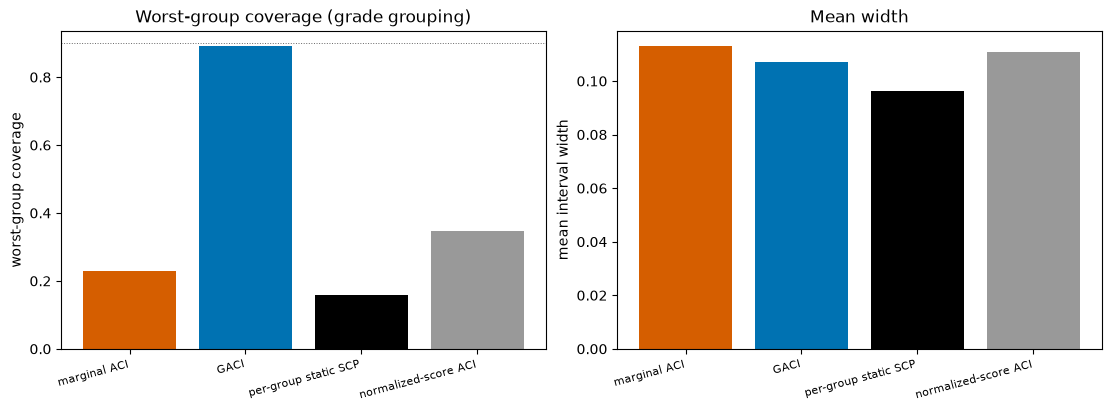

grade-G coverage: {'marginal ACI': 0.23, 'GACI': 0.892, 'per-group static SCP': 0.157, 'normalized-score ACI': 0.348}


In [4]:
g10 = m10["groupings"]["grade"]
methods = ["aci", "gaci", "scp_group", "aci_norm"]
labels = {"aci": "marginal ACI", "gaci": "GACI",
          "scp_group": "per-group static SCP",
          "aci_norm": "normalized-score ACI"}
worst = [g10[m]["worst_group_coverage"] for m in methods]
width = [g10[m]["mean_width"] for m in methods]
g_cov = [g10[m]["per_group"]["G"]["coverage"] for m in methods]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
colors = [COLORS.get(m.upper(), "#999999") for m in methods]
colors[methods.index("scp_group")] = "#000000"
colors[methods.index("aci_norm")] = "#999999"
ax1.bar(range(len(methods)), worst, color=colors)
ax1.axhline(TARGET, color="k", lw=0.7, ls=":", alpha=0.6)
ax1.set_xticks(range(len(methods)), [labels[m] for m in methods],
               rotation=15, ha="right", fontsize=8)
ax1.set_ylabel("worst-group coverage")
ax1.set_title("Worst-group coverage (grade grouping)")
ax2.bar(range(len(methods)), width, color=colors)
ax2.set_xticks(range(len(methods)), [labels[m] for m in methods],
               rotation=15, ha="right", fontsize=8)
ax2.set_ylabel("mean interval width")
ax2.set_title("Mean width")
for ax in (ax1, ax2):
    ax.tick_params(axis="x", labelsize=8)
plt.show()
print("grade-G coverage:", {labels[m]: round(g_cov[i], 3)
                              for i, m in enumerate(methods)})

## 4. Block-level stability (E5)

Ten contiguous stream blocks: per-block worst-group coverage for marginal
ACI vs GACI on the grade grouping. The gap is stable across the stream —
structural, not a single-regime artifact.

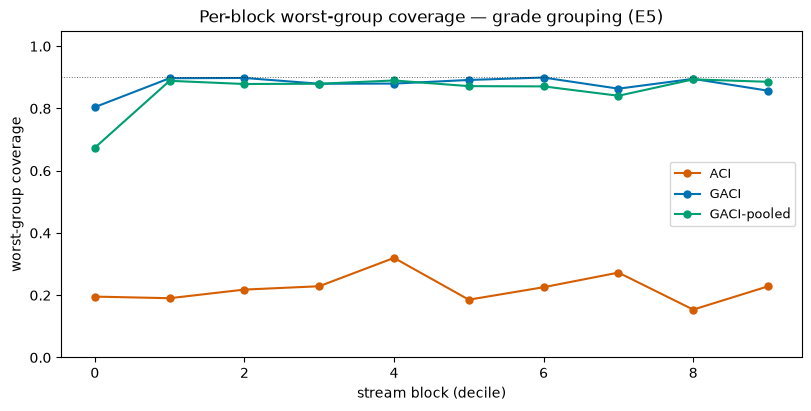

In [5]:
blk = m5["block_analysis"]["grade"]
fig, ax = plt.subplots(figsize=(8, 4), layout="constrained")
for name, key in [("ACI", "aci"), ("GACI", "gaci"),
                   ("GACI-pooled", "gaci_pooled")]:
    rows = blk[key]
    xs = [r["block"] for r in rows]
    ys = [r["worst_group"] for r in rows]
    ax.plot(xs, ys, "o-", color=COLORS.get(name, "#999999"),
            label=name, ms=5)
ax.axhline(TARGET, color="k", lw=0.7, ls=":", alpha=0.6)
ax.set_xlabel("stream block (decile)")
ax.set_ylabel("worst-group coverage")
ax.set_ylim(0, 1.05)
ax.legend(fontsize=9)
ax.set_title("Per-block worst-group coverage — grade grouping (E5)")
plt.show()

## 5. Coverage-vs-width frontier across experiments (E4/E5/E6)

Every (method × grouping × domain) point. Marker shape encodes domain
(circle = Lending Club, square = Electricity); color encodes method. GACI
moves points *up* (coverage) without moving them *right* (width) — the
reallocation story in frontier form.

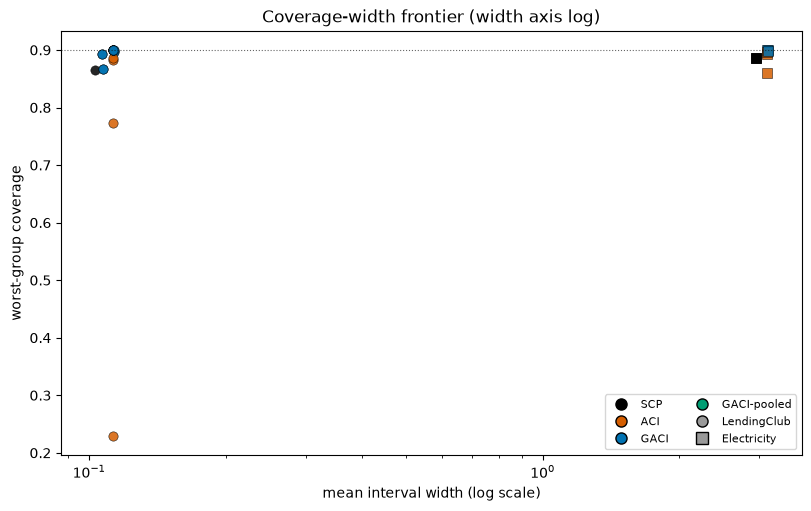

31 frontier points plotted


In [6]:
def frontier_points():
    pts = []
    # E4 grade grouping (Lending Club, ridge)
    for m, e in [("SCP", m4["scp"]), ("ACI", m4["aci"]),
                 ("GACI", m4["gaci"]), ("GACI-pooled", m4["gaci_pooled"])]:
        pts.append(("LendingClub", m, e["mean_width"],
                     e.get("worst_group_coverage", e["marginal_coverage"])))
    # E5 groupings (Lending Club, ridge) — all six
    for gname, g in m5["groupings"].items():
        for m in ("aci", "gaci", "gaci_pooled"):
            e = g[m]
            pts.append(("LendingClub", m.upper().replace("_", "-"),
                         e["mean_width"], e["worst_group_coverage"], gname))
    # E6 electricity groupings
    for gname, g in m6["groupings"].items():
        for m in ("scp", "aci", "gaci"):
            e = g[m]
            w = e.get("mean_width")
            cov = e.get("worst_group_coverage", e["marginal_coverage"])
            pts.append(("Electricity", m.upper(), w, cov, gname))
    return pts

pts = frontier_points()
fig, ax = plt.subplots(figsize=(8, 5), layout="constrained")
dom_marker = {"LendingClub": "o", "Electricity": "s"}
for dom, meth, w, c, *rest in pts:
    grp = rest[0] if rest else ""
    base = meth.split("-")[0]
    ax.scatter(w, c, marker=dom_marker[dom], s=45,
               color=COLORS.get(base, "#999999"), alpha=0.85,
               edgecolors="k", linewidths=0.4)
ax.axhline(TARGET, color="k", lw=0.8, ls=":", alpha=0.6)
ax.set_xscale("log")
ax.set_xlabel("mean interval width (log scale)")
ax.set_ylabel("worst-group coverage")
ax.set_title("Coverage-width frontier (width axis log)")
# legend proxies
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="o", color="w", markerfacecolor=v,
                  markeredgecolor="k", markersize=8, label=k)
           for k, v in COLORS.items()]
handles += [Line2D([], [], marker=m, color="w", markerfacecolor="#999999",
                  markeredgecolor="k", markersize=8, label=d)
           for d, m in dom_marker.items()]
ax.legend(handles=handles, fontsize=8, loc="lower right", ncol=2)
plt.show()
print(f"{len(pts)} frontier points plotted")

## 6. Key numbers cheat-sheet

| Claim | Value | Source |
|---|---|---|
| ACI grade-G coverage | 0.230 | `e4_metrics.json` |
| GACI grade-G coverage | 0.892 | `e4_metrics.json` |
| Mean width ACI / GACI | 0.113 / 0.107 | `e4_metrics.json` |
| Grade-G width ACI / GACI | 0.114 / 0.208 | `e4_metrics.json` |
| E10: static SCP / norm-ACI on G | 0.157 / 0.348 | `e10_metrics.json` |
| Electricity hour-band worst | 0.865 → 0.900 | `e6_metrics.json` |
| Unseen-group cold-start (E9) | 0.892 vs marginal 0.869 | `e9_metrics.json` |

Canonical figures: `results/figures/fig1_coverage_trajectory.png`,
`fig2_frontier.png` (regenerate via `experiments/figures.py`).